In [1]:
# Load the enviroonment API from the file like this so that we can secure api pin whenever we want it to upload on github

import os
from dotenv import load_dotenv

# Load the file where you saved the key
load_dotenv(".env.local")

# Read the variable into your code
API_KEY = os.getenv("MY_API_KEY")

In [2]:
# Make your first API request
# Convert the API response into pandas DataFrame
 
import requests # it is a pyhton library used to send HTTP requests to web servers and get data back
import pandas as pd

API_KEY = API_KEY

url="https://www.alphavantage.co/query"

params={
    "function" : "TIME_SERIES_DAILY",  #Tells the server what kind of report to run.In this case,daily trading numbers for each day
    "symbol" : "RELIANCE.BSE", # Tells the server which asset you want."RELIANCE" is the stock ticker, and ".BSE" targets the BombayStock Exchange
    "outputsize" : "compact", # Tells the server how much history to fetch."Compact" returns only the latest 100 days
    "apikey" : API_KEY # Tells the server who you are.It passes your personal key/token so the server can verify your account and grant access
}

response = requests.get(url, params=params) # It is a parcel delivered back to you by the website

print(response.status_code) # Tells you if the request worked or failed.it returned 200,which is the internet's standad code for "Success/Ok"
print(response.json()) #Converts the incoming text data into a python dictionary.when the websites sends data back it arrives as plain text

data=response.json()

time_series = data["Time Series (Daily)"] # Extracts only the daily price data or filter out metadata, keeps daily prices

df=pd.DataFrame.from_dict( # Converts daily price data into a table with dates as rows
    time_series,
    orient="index"
)

print(df.head())

200
{'Meta Data': {'1. Information': 'Daily Prices (open, high, low, close) and Volumes', '2. Symbol': 'RELIANCE.BSE', '3. Last Refreshed': '2026-10-12', '4. Output Size': 'Compact', '5. Time Zone': 'US/Eastern'}, 'Time Series (Daily)': {'2026-10-12': {'1. open': '1180.0000', '2. high': '1185.6500', '3. low': '1153.1000', '4. close': '1159.0000', '5. volume': '796600'}, '2026-10-09': {'1. open': '1179.5000', '2. high': '1189.0500', '3. low': '1160.4000', '4. close': '1170.8000', '5. volume': '2089919'}, '2026-10-08': {'1. open': '1208.0000', '2. high': '1209.0000', '3. low': '1173.0000', '4. close': '1177.3000', '5. volume': '1451738'}, '2026-10-07': {'1. open': '1214.9000', '2. high': '1221.0000', '3. low': '1203.6000', '4. close': '1206.6500', '5. volume': '568645'}, '2026-10-06': {'1. open': '1189.9000', '2. high': '1219.0000', '3. low': '1188.1500', '4. close': '1219.0000', '5. volume': '675671'}, '2026-10-05': {'1. open': '1172.9500', '2. high': '1192.7500', '3. low': '1172.2000',

In [3]:
# Clean the column names

df=df.rename(columns={
   "1. open":"open",
   "2. high":"high",
   "3. low":"low",
   "4. close":"close",
   "5. volume":"volume"
})

In [4]:
# Convert date:
df.index=pd.to_datetime(df.index) # It turns the date text into real calendar dates so python can sort,filter and plot them properly by time

In [5]:
# Convert numbers:
# It converts the stock prices and volume from text/string into actual numbers
df["open"] = pd.to_numeric(df["open"])
df["high"] = pd.to_numeric(df["high"])
df["low"] = pd.to_numeric(df["low"])
df["close"] = pd.to_numeric(df["close"])
df["volume"] = pd.to_numeric(df["volume"])

In [6]:
# Reset the index:
# This turns the dates into a normal table column and lables that columns "date"
df=df.reset_index()
df=df.rename(columns={
    "index" : "date"
})

In [7]:
# Add the company namme

df["company"] = "Reliance"
df["symbol"] = "RELIANCE.BSE"
df["sector"] = "Energy"

In [8]:
# Save the raw data

import os
# we imoprt os because it is python's build in module for interacting with the operating system and the computers file system

# create the folder path if it dosen't exist
os.makedirs("data/raw" ,  exist_ok=True)

# save the raw data
df.to_csv("data/raw/reliance_raw.csv", index = False)

In [ ]:
# Import multiple companies

def get_stock_data(symbol, company, sector): #This function takes three inputs: the stock ticker symbol, the company name, and the sector name.
    params = {
        "function" : "TIME_SERIES_DAILY",#Tells the server what kind of report to run.In this case,daily trading numbers for each day
        "symbol" : "symbol",# Tells the server which asset you want."RELIANCE" is the stock ticker, and "BSE" targest the Bombay stock exchange    
        "outputsize" : "compact", # Tells the server how much history to fetch. "compact" returns only the latest 100 days
        "apikey" : "API_KEY" # Tells the server who you are. It passes your personal key/token so the server can verify your account and grant access
    }

    response = requests.get(url,params=params) # It is a parcel delivered back to you by the website
    data = response.json() # This converts the incoming text data into a python dictionary. when the website sends data back it arrives as plain text
    time_series = data["Time Series (Daily)"] # Extract the daily price records from API response
    df=pd.DataFrame.from_dict(
        time_series,
        orient="index"
    ) # convert dictionary to dataframe with dates as rows

    # clean the column names
    df=df.rename(columns={
        "1. open": "open",
        "2. high": "high",
        "3. low": "low",
        "4. close": "close",
        "5. volume": "volume",

    })

    df.index = pd.to_datetime(df.index) # It turns the date text into real calendar dates so python can sort,filter and plot them properly by time
    df=df.reset_index() # This turns the dates into a normal table column and labels that columns "date"
    df=df.rename(columns={"index":"date"}) # Rename the index column to "date"
    for column in ["open","high","low","close","volume"]: # It converts the stock prices and volume from text/string into actual numbers
        df[column]=pd.to_numeric(df[column]) 
        df["company"]=company
        df["symbol"]=symbol
        df["sector"]=sector
        return df






In [ ]:
# Define a list of companies to fetch data for

companies = [
    ("RELIANCE.BO", "Reliance", "Energy"),
    ("TCS.BO","TCS","IT"),
    ("INFY.BO","Infosys","IT"),
    ("HDFCBANK.BO","HDFC Bank","Banking"),
    ("ICICIBANK.BO", "ICICI Bank", "Banking")

]

In [ ]:
import requests # Used to send HTTp requests to web servers and get data baack
import pandas as pd # Used for data manipulation, cleaning, and creating dataframes

API_KEY=API_KEY

def get_stock_data(symbol,company,sector): # Function to fetch stock data for a given symbol,company name and sector name
    url="https://www.alphavantage.co/query" # API endpoint for fetching stock data from Alpha vantage

    params={"function" : "TIME_SERIES_DAILY",
            "symbol" : symbol,
            "outputsize":"compact",
            "apikey":API_KEY
            }

    response=requests.get(url, params=params, timeout=30) # It is a parcel delivered back to you by the website

    if response.status_code !=200: # check if the request was successful (status code 200 means success)
        print("HTTP Error:" , response.status_code) # print the error code if the request failed
        return None

    data = response.json() # This converts the incoming text data into a python dictionary. when the website sends data back it arrives as plain text

    # check wether the API returned an error
    if "Time Series (Daily)" not in data:
        print(f"Error fetching {company}:")
        print(data)
        return None

    # Convert API data into a Dataframe
    df=pd.DataFrame.from_dict(
        data["Time Series (Daily)"],
        orient="index"
    )

    # Rename columns
    df.columns=[
        "open",
        "high",
        "low",
        "close",
        "volume"
    ]

    # Convert index to datetime
    df.index = pd.to_datetime(df.index)

    # Convert columns to numeric
    df = df.apply(pd.to_numeric , errors="coerce")

    # Add Company information
    df["company"] = company
    df["symbol"] = symbol
    df["sector"] = sector

    # Make date a normal column
    df.index.name = "date"
    df = df.reset_index()

    return df

In [ ]:
import time # Used to pause the program for a specified number of seconds between API requests to avoid hitting rate limits

all_data = [] # Empty list to store the dataframes for each company

for symbol, company, sector in companies: # Iterate over the list of companies and fetch stock data for each one
    print(f"Fetching {company}...") # Display progress for the company currently being processed

    df=get_stock_data(symbol, company, sector) # call the function to fetch stock data for the current company and store it in a dataframe
    if df is not None: # If the dataframe is not empty, append it to the list of all dataframes
        all_data.append(df) # Pause for 12 seconds to avoid hitting the API rate limit
        time.sleep(12) # pause for 12 seconds to avoid hitting the API rate limit

# Combine all company data
if all_data:
    final_df = pd.concat(all_data, ignore_index=True)  
    print(final_df.head())
    print("Total rows :" , len(final_df))
else:
    print("No stock data was retrieved")      

Fetching Reliance...
Fetching TCS...
Fetching Infosys...
Fetching HDFC Bank...
Fetching ICICI Bank...
        date    open     high      low    close   volume   company  \
0 2026-10-12  1180.0  1185.65  1153.10  1159.00   796600  Reliance   
1 2026-10-09  1179.5  1189.05  1160.40  1170.80  2089919  Reliance   
2 2026-10-08  1208.0  1209.00  1173.00  1177.30  1451738  Reliance   
3 2026-10-07  1214.9  1221.00  1203.60  1206.65   568645  Reliance   
4 2026-10-06  1189.9  1219.00  1188.15  1219.00   675671  Reliance   

        symbol  sector  
0  RELIANCE.BO  Energy  
1  RELIANCE.BO  Energy  
2  RELIANCE.BO  Energy  
3  RELIANCE.BO  Energy  
4  RELIANCE.BO  Energy  
Total rows : 500


In [ ]:
# Combine individual company dataframes into a single dataframe
stock_data = pd.concat(
    all_data,
    ignore_index=True
)

In [14]:
# Perform data-quality checks

In [15]:
# Mssing values
print(stock_data.isnull().sum())

date       0
open       0
high       0
low        0
close      0
volume     0
company    0
symbol     0
sector     0
dtype: int64


In [16]:
# Duplicate rows
print(stock_data.duplicated().sum())

0


In [17]:
# Data types

print(stock_data.dtypes)

date       datetime64[ns]
open              float64
high              float64
low               float64
close             float64
volume              int64
company            object
symbol             object
sector             object
dtype: object


In [18]:
# Number of records
print(stock_data.shape)

(500, 9)


In [19]:
# Date range
print(stock_data["date"].min())
print(stock_data["date"].max())

2026-05-20 00:00:00
2026-10-12 00:00:00


In [20]:
# Print unique companies
print(stock_data["company"].unique())

['Reliance' 'TCS' 'Infosys' 'HDFC Bank' 'ICICI Bank']


In [21]:
# This outputs a table with exactly one row per unique company
stock_data.groupby("company").first()

,date,open,high,low,close,volume,symbol,sector
company,,,,,,,,
HDFC Bank,2026-10-12,708.6,712.00,700.3,704.2500,673469,HDFCBANK.BO,Banking
ICICI Bank,2026-10-12,1354.0,1357.00,1334.4,1345.0000,220256,ICICIBANK.BO,Banking
Infosys,2026-10-12,1029.0,1033.55,1010.4,1017.0000,1432127,INFY.BO,IT
Reliance,2026-10-12,1180.0,1185.65,1153.1,1159.0000,796600,RELIANCE.BO,Energy
TCS,2026-10-12,2180.0,2195.00,2121.0,2126.8999,328473,TCS.BO,IT


In [22]:
# Calculate daily return
# formula
# Daily Return = (Current close - Previous Close) / previous Close

In [23]:
# In Pandas
stock_data = stock_data.sort_values(
    ["company" , "date"]
) # Sort the dataframe rows chronologically for each individual company

stock_data["daily_return"] = (
    stock_data.groupby("company")["close"].pct_change()
)# This statement computes the day-over-day percentage change in closing price for each individual company and stores the result in a new column called "daily return"

In [24]:
# Convert to percentage

stock_data["daily_return_pct"]=(stock_data["daily_return"]*100)

In [25]:
# Calculate cumulative return
# Here Cumulative return defines the total percentage profit or loss as investor has made on each stock from the day you bought it until today,shown as a percentage
stock_data["cumulative_return"]=stock_data.groupby("company")["daily_return"].transform(lambda x: (1+x).cumprod() -1)

In [26]:
# Convert to percentage
stock_data["cumulative_return_pct"]=(
    stock_data["cumulative_return"]*100
)

In [27]:
# Calculate Volatility
# Here, daily volatility measures the typical daily price swing or risk of a stock
# for begginer porject, use standard deviation of daily returns

In [28]:
volatility=(
    stock_data.groupby("company")["daily_return"].std()
)
# In this code, daily volatility calculates the sample standard deviation of daily returns for each company
# It answers : By how many percentage points does this stock typically deviate from its average daily return

In [29]:
# Annualized volatility
annual_volatiltiy=volatility*(252 ** 0.5)
# why 252 because approximately 252 trading days occur in a typical year
# it answers: How risky or wild are this stocks price swings over a full year compared to other investments ?? and is this potential profit really worth that level of risk

In [30]:
# Calculate Moving averages
stock_data["MA20"]=(
    stock_data.groupby("company")["close"].transform(lambda x: x.rolling(20).mean())
)

# it answers : Is the stock genuinely trending up or down after filtering daily up and down trends

In [31]:
# 50-day
stock_data["MA50"] = (
    stock_data.groupby("company")["close"].transform(lambda x : x.rolling(50).mean())
)
# This allows you to analyze price trends and make you to understand does stock is trending up or down after filtering daily up and daily down

In [32]:
# Calculate trading volume metrics

stock_data["volume_MA20"]=(stock_data.groupby("company")["volume"].transform(lambda x : x.rolling(20).mean()))

# Does the price movement have strong institutional volume behind it??

In [33]:
# Then identify unusually high-volume days:
# The formula checks wether today's trading volume is at least 50 percent higher than normal
# why we took 50 percent : here we took 50 percent because it is standard financial metrics that separates genuine market anomailes from normal daily volatility

stock_data["high_volume"] = (
    stock_data["volume"]>stock_data["volume_MA20"]*1.5
)

# Business question: which companies experienced unusual trading activity

In [34]:
# Calculate maximum drawdown
# In finance,Drawdown measures how far a stocks price has fallen from its highest peak up to that point
# This is a useful finance/business mertic

In [35]:
# The code calculates the highest closing price seen so far (the historical peak price) for each company up to that specified day
# .cummax() stands for cumulative maximum
# .cummax() tracks the all-time peak price reached up to each day

stock_data["rolling_max"] = ( stock_data.groupby("company")["close"].cummax())

In [36]:
# Step 1 : calculate the rolling peak price for each company
stock_data["rolling_max"] = stock_data.groupby("company")["close"].cummax()

# Step 2 : Compute the drawdown percentage(The missing step)
stock_data["drawdown"] = (stock_data["close"] - stock_data["rolling_max"]) / stock_data["rolling_max"]

# Step 3: Find the wrost (minimum) drawdown for each company
max_drawdown = stock_data.groupby("company")["drawdown"].min()

print(max_drawdown)

# In summary , a negative drawdown means the stock is trading below its previous peak

company
HDFC Bank    -0.171738
ICICI Bank   -0.124818
Infosys      -0.224513
Reliance     -0.152065
TCS          -0.190311
Name: drawdown, dtype: float64


In [37]:
# Create a summary table

In [38]:
summary = (
    stock_data.groupby(["company" , "sector"]).agg(average_price=("close" , "mean"),total_volume =("volume" , "sum"),
    average_daily_return =("daily_return","mean"), volatility =("daily_return","std"),maximum_drawdown = ("drawdown","min")).reset_index()
)

In [39]:
# Now do actual analysis

In [40]:
# which sector performed best

sector_return = (stock_data.groupby("sector")["daily_return"].mean())
print(sector_return)

sector
Banking    0.000117
Energy    -0.001471
IT        -0.000850
Name: daily_return, dtype: float64


In [41]:
# Which company generated the highest percentage return ?
# calculate daily percentage return

stock_data["daily_return"]=(stock_data.groupby("company")["close"].pct_change()*100)

print(stock_data[["date", "company", "close", "daily_return"]].head(10))

          date    company   close  daily_return
399 2026-05-20  HDFC Bank  759.50           NaN
398 2026-05-21  HDFC Bank  759.05     -0.059250
397 2026-05-22  HDFC Bank  766.40      0.968316
396 2026-05-25  HDFC Bank  786.85      2.668319
395 2026-05-26  HDFC Bank  779.00     -0.997649
394 2026-05-27  HDFC Bank  758.50     -2.631579
393 2026-05-29  HDFC Bank  744.75     -1.812788
392 2026-06-01  HDFC Bank  742.65     -0.281974
391 2026-06-02  HDFC Bank  748.70      0.814650
390 2026-06-03  HDFC Bank  753.65      0.661146


In [42]:
# Calculate total price return

# claculate first and last closing prices
returns = (stock_data.groupby("company").agg(first_close=("close","first"),last_close=("close","last")).reset_index())

# Calculate total price return
returns["return_pct"]=((returns["last_close"] - returns["first_close"])/returns["first_close"])*100

# Sort companies from highest to lowest return
returns = returns.sort_values("return_pct",ascending=False)

print(returns)

      company  first_close  last_close  return_pct
1  ICICI Bank       1237.5   1345.0000    8.686869
4         TCS       2276.7   2126.8999   -6.579703
0   HDFC Bank        759.5    704.2500   -7.274523
2     Infosys       1174.4   1017.0000  -13.402589
3    Reliance       1349.7   1159.0000  -14.129066


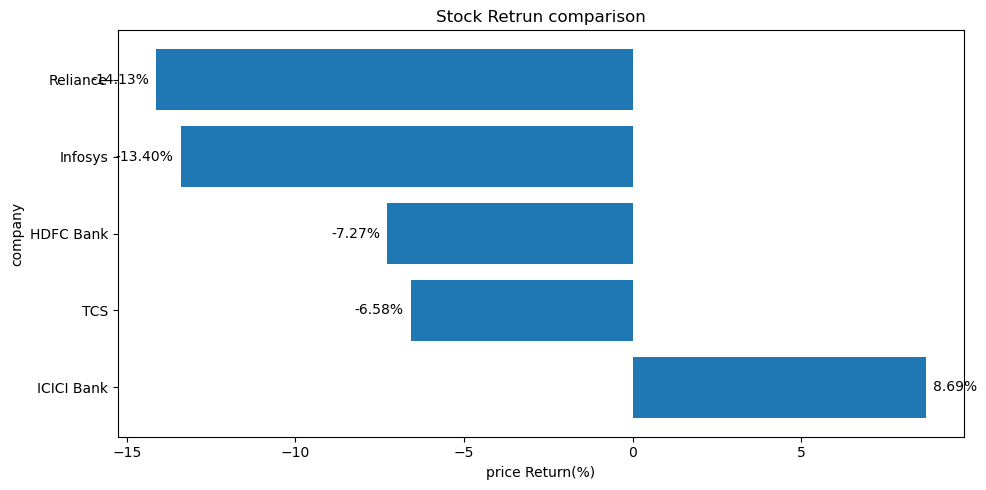

In [43]:
# Visualize the returns

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

bars = plt.barh(returns["company"],returns["return_pct"])

plt.bar_label(bars, fmt="%.2f%%", padding=5)

plt.xlabel("price Return(%)")
plt.ylabel("company")
plt.title("Stock Retrun comparison")

plt.tight_layout()
plt.show()

# Result : You will see all companies in your dataset , ranked by their calculated price returns

In [44]:
# Find the most volatile stock
# which company experienced the largest price fluctuations??
# Volatility measures how much daily returns vary
# Here we will calculate the daily return volatiltiy for each company

volatility = (stock_data.groupby("company")["daily_return"].std().reset_index(name="daily_volatility_pct"))

volatility = volatility.sort_values("daily_volatility_pct",ascending=False)

print(volatility)

      company  daily_volatility_pct
4         TCS              2.107657
2     Infosys              2.107655
0   HDFC Bank              1.367470
3    Reliance              1.162172
1  ICICI Bank              1.120142


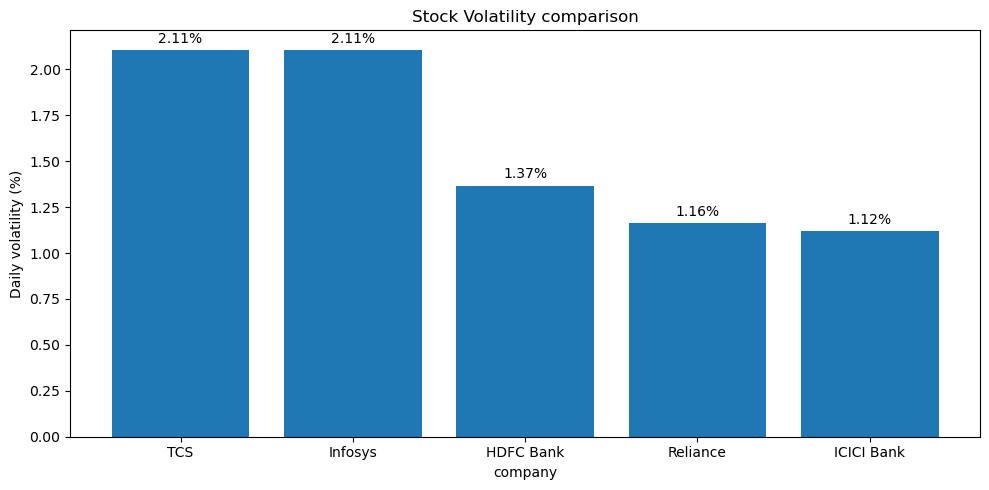

In [45]:
# Create a chart
plt.figure(figsize=(10,5))

bars = plt.bar(volatility["company"],volatility["daily_volatility_pct"])

plt.bar_label(bars, fmt="%.2f%%",padding=3)

plt.xlabel("company")
plt.ylabel("Daily volatility (%)")
plt.title("Stock Volatility comparison")

plt.tight_layout()
plt.show()

In [46]:
# Find the company with the highest average trading volume
# which company had the highest average daily trading volume??

average_volume = (stock_data.groupby("company")["volume"].mean().reset_index(name="average_daily_volume"))

average_volume = average_volume.sort_values("average_daily_volume",ascending=False)
print(average_volume)

      company  average_daily_volume
0   HDFC Bank            2122948.02
3    Reliance            1008943.51
1  ICICI Bank             953433.58
2     Infosys             718203.59
4         TCS             257816.11


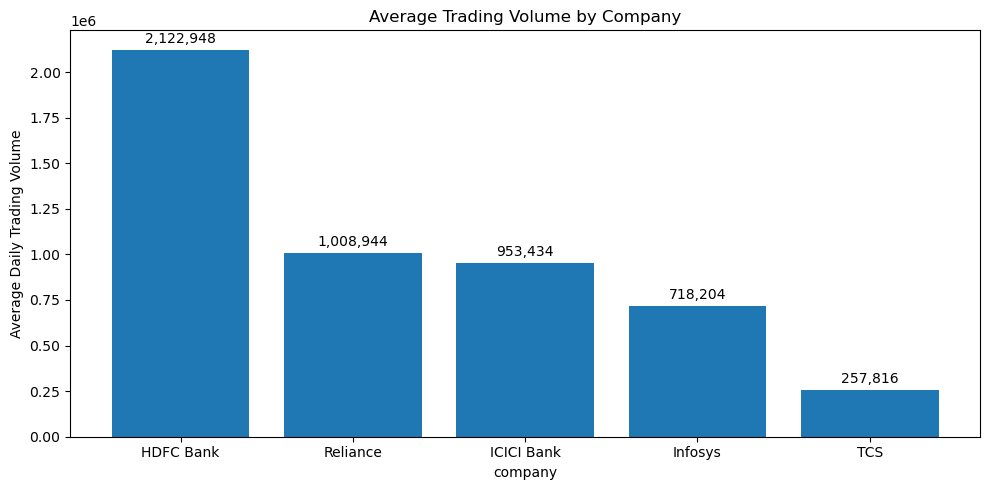

In [47]:
# Create a chart

plt.figure(figsize=(10,5))

bars = plt.bar(average_volume["company"],average_volume["average_daily_volume"])

plt.bar_label(bars,labels=[f"{value:,.0f}" for value in average_volume["average_daily_volume"]], padding=3)

plt.xlabel("company")
plt.ylabel("Average Daily Trading Volume")
plt.title("Average Trading Volume by Company")

plt.tight_layout()
plt.show()

In [48]:
# Find the largest sinlge-day price drop
# Which company experienced the largest daily price decline ??
# Find the row with the lowest daily return

largest_drop = stock_data.loc[
stock_data["daily_return"].idxmin()
]

print("company:", largest_drop["company"])
print("Date :",largest_drop["date"].date())
print("Daily return:",round(largest_drop["daily_return"],2), "%")

company: TCS
Date : 2026-06-03
Daily return: -8.43 %


In [49]:
# Calculate 20-day and 50-day moving averages

# 20-day moving average
stock_data["MA20"] = (stock_data.groupby("company")["close"].transform(lambda prices:prices.rolling(20).mean()))

# 50-day moving averages
stock_data["MA50"] = (stock_data.groupby("company")["close"].transform(lambda prices:prices.rolling(50).mean()))

# Print
print(stock_data[["date", "company", "close", "MA20", "MA50"]].tail(10))

          date company      close         MA20         MA50
109 2026-09-29     TCS  2036.0000  2182.397490  2280.656994
108 2026-09-30     TCS  2050.0000  2167.647490  2277.479992
107 2026-10-01     TCS  2079.3000  2156.012490  2274.220992
106 2026-10-02     TCS  2079.3000  2144.932495  2270.728994
105 2026-10-05     TCS  2108.3501  2136.780005  2266.992998
104 2026-10-06     TCS  2098.0000  2128.680005  2260.996998
103 2026-10-07     TCS  2084.0000  2122.430005  2253.764996
102 2026-10-08     TCS  2075.2500  2115.367505  2246.631998
101 2026-10-09     TCS  2163.0000  2113.417505  2242.579996
100 2026-10-12     TCS  2126.8999  2109.662500  2236.117994


In [50]:
# Compare IT,Banking and Energy Sectors
# Which sector generated the highest average stock return??

# Calculate total price return for each company
company_returns = (stock_data.groupby(["company","sector"]).agg(first_close=("close","first"),last_close=("close","last")).reset_index())

company_returns["return_pct"] = ((company_returns["last_close"] - company_returns["first_close"])/company_returns["first_close"])*100

# Calculate average company return by sector
sector_returns = (company_returns.groupby("sector")["return_pct"].mean().reset_index(name="averge_return_pct"))

print(sector_returns)

    sector  averge_return_pct
0  Banking           0.706173
1   Energy         -14.129066
2       IT          -9.991146


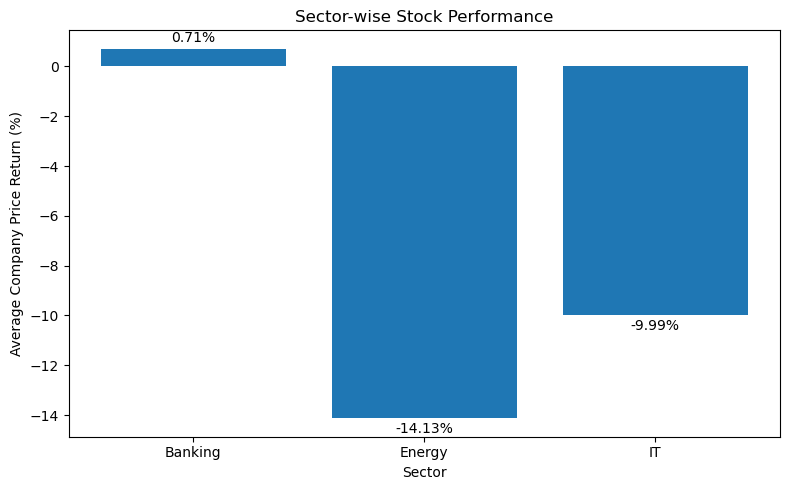

In [51]:
# Create a sector comparison chart

plt.figure(figsize = (8,5))

bars = plt.bar(sector_returns["sector"], sector_returns["averge_return_pct"])

plt.bar_label(bars, fmt="%.2f%%",padding=3)

plt.xlabel("Sector")
plt.ylabel("Average Company Price Return (%)")
plt.title("Sector-wise Stock Performance")

plt.tight_layout()
plt.show()

In [52]:
# Compare IT stocks with banking stocks
# Did IT stocks perform better than banking stocks

# Filter IT and Banking companies
selected_sectors = company_returns[company_returns["sector"].isin(["IT","Banking"])]

# Compare average returns
it_vs_banking = (selected_sectors.groupby("sector")["return_pct"].mean().reset_index(name="average_return_pct"))

print(it_vs_banking)

    sector  average_return_pct
0  Banking            0.706173
1       IT           -9.991146


In [53]:
# Find the highest closing price for each company
# Which company reached its highest closing price during the analysis period ??

highest_prices = (stock_data.loc[stock_data.groupby("company")["close"].idxmax(),["company", "date", "close"]].sort_values("close", ascending=False).reset_index(drop=True))

print(highest_prices)

      company       date    close
0         TCS 2026-08-07  2453.70
1  ICICI Bank 2026-08-06  1476.95
2    Reliance 2026-05-25  1366.85
3     Infosys 2026-06-02  1270.75
4   HDFC Bank 2026-07-06   829.75


In [54]:
# Find the day with the highest trading volume for each company
# on which day did each company experience its highest trading volume??

highest_volume_days = (stock_data.loc[stock_data.groupby("company")["volume"].idxmax(),["company","date","volume","close"]].sort_values("volume",ascending=False).reset_index(drop=True))
print(highest_volume_days)

      company       date    volume    close
0  ICICI Bank 2026-09-25  22674495  1326.50
1   HDFC Bank 2026-08-21   8163779   727.50
2    Reliance 2026-06-10   4063671  1259.55
3     Infosys 2026-07-29   3397525  1155.50
4         TCS 2026-06-03   1148517  2241.70


In [55]:
# Calculate the largest price decline from a previous peak
# calculate maximum drawdown for each company
drawdown_results = []

for company, group in stock_data.groupby("company"):

    group = group.sort_values("date").copy()

# Highest closing price observed up to each date
group["running_peak"] = group["close"].cummax()

# Percentage decline from the running peak
group["drawdown_pct"] = (group["close"] - group["running_peak"])/group["running_peak"]* 100

# Most negative drawdown
worst_drawdown = group["drawdown_pct"].min()

drawdown_results.append({"company":company,"maximum_drawdown_pct":worst_drawdown})

drawdown_df = pd.DataFrame(drawdown_results)

drawdown_df = drawdown_df.sort_values("maximum_drawdown_pct")
print(drawdown_df)



  company  maximum_drawdown_pct
0     TCS            -19.031089


In [56]:
# Check whether higher volume coincided with price changes
# Did days with unusually high trading volume also experience larger price moevments??

# calculate absolute daily price return
stock_data["absolute_return"] = stock_data["daily_return"].abs()

# Calculate correlation for each company
volume_return_correlation = (stock_data.groupby("company").apply(lambda group:group["volume"].corr(group["absolute_return"]),include_groups=False).reset_index(name="volume_return_correlation"))
print(volume_return_correlation)

      company  volume_return_correlation
0   HDFC Bank                   0.007437
1  ICICI Bank                  -0.031103
2     Infosys                   0.521209
3    Reliance                   0.245107
4         TCS                   0.725256


In [57]:
# Save your analysis results

# save the main dataset with calculated metrics
stock_data.to_csv("stock_analysis_results.csv", index=False)

# save company return comparison
returns.to_csv("company_returns.csv", index=False)

# Save the return comparison
sector_returns.to_csv("sector_return.csv",index=False)

# save volatility results
volatility.to_csv("stock_volatility.csv",index=False)

print("Analysis results saved successfully.")

Analysis results saved successfully.


In [58]:
# Create visualization in python

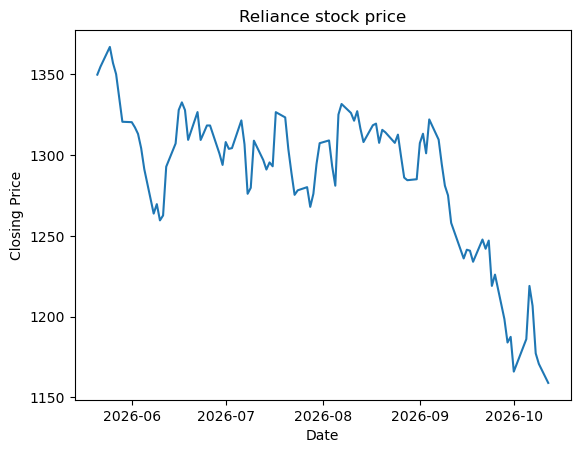

In [59]:
import matplotlib.pyplot as plt

company_data = stock_data[stock_data["company"] == "Reliance"]

plt.plot(company_data["date"],
         company_data["close"])

plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("Reliance stock price")
plt.show()

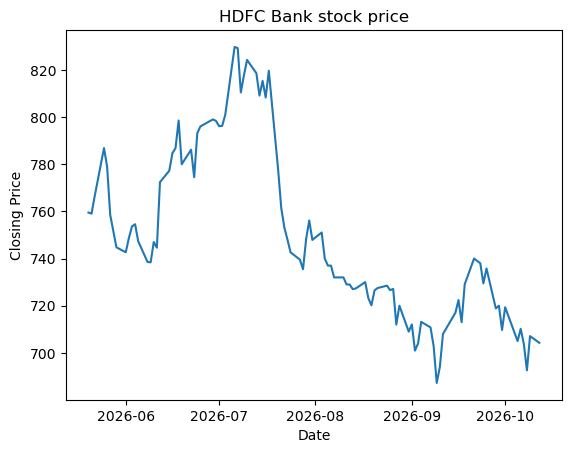

In [60]:
import matplotlib.pyplot as plt
company_data = stock_data[stock_data["company"] == "HDFC Bank"]

plt.plot(company_data["date"],
         company_data["close"])

plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("HDFC Bank stock price")
plt.show()

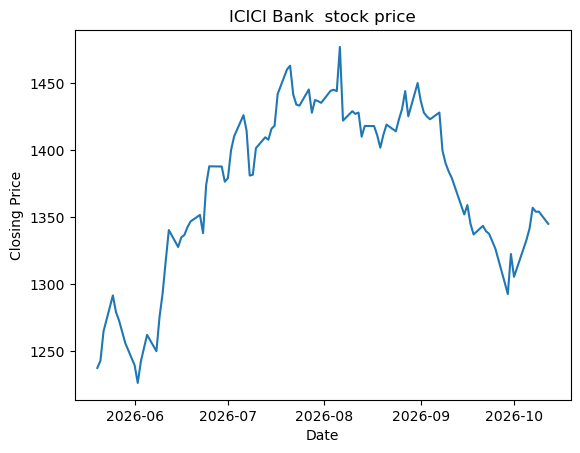

In [61]:
company_data = stock_data[stock_data["company"] == "ICICI Bank"]

plt.plot(company_data["date"],
         company_data["close"])

plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("ICICI Bank  stock price")
plt.show()

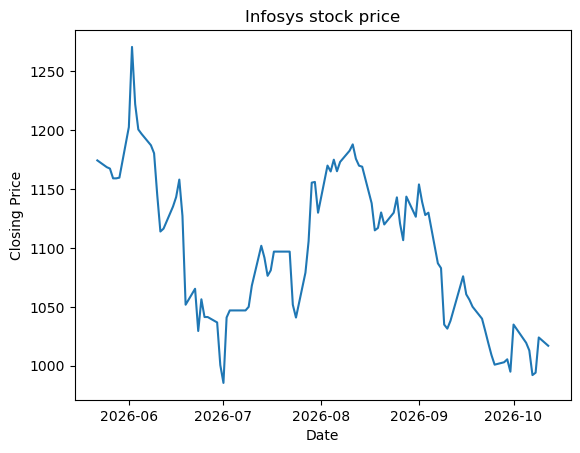

In [62]:
company_data = stock_data[stock_data["company"] == "Infosys"]

plt.plot(company_data["date"],
         company_data["close"])

plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("Infosys stock price")
plt.show()

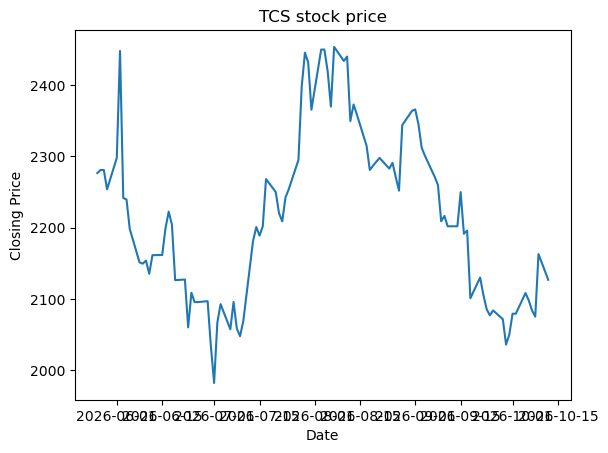

In [63]:
company_data = stock_data[stock_data["company"] == "TCS"]

plt.plot(company_data["date"],
         company_data["close"])

plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("TCS stock price")
plt.show()

In [64]:
# Create a bar chart comapring the returns of TCS,Reliance,Infosys,ICICI Bank and HDFC Bank

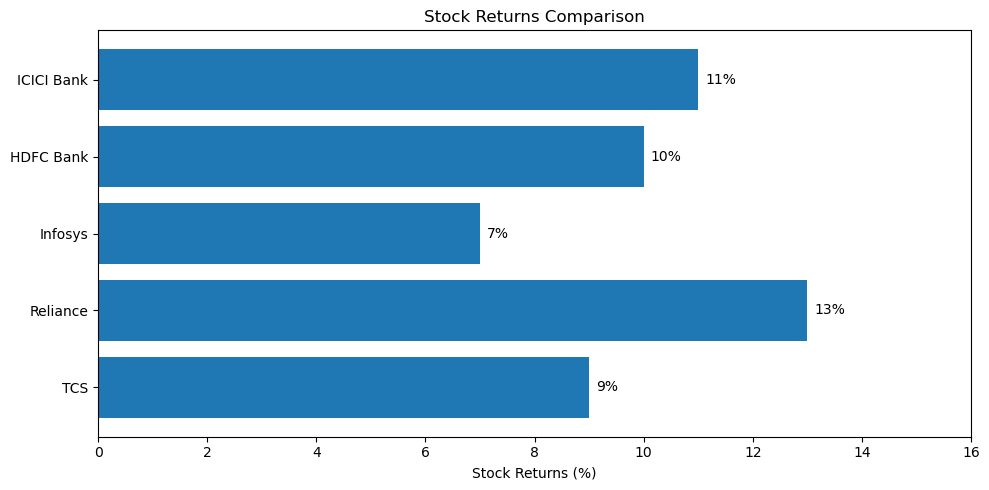

In [65]:
import matplotlib.pyplot as plt

# Stock return percentages
companies = ["TCS", "Reliance", "Infosys", "HDFC Bank", "ICICI Bank"]
returns = [9,13,7,10,11]
# Examples values; replace with actual returns

# Create horizontal bar chart
plt.figure(figsize=(10,5)) # here 10(inches) is the width of the chart and 5(inches) is the height of the chart
bars = plt.barh(companies, returns) # plt.barh creates a hoorizontal bar chart where the y-axis represnts the companies and the x-axis represents the stock returns in percentage

# Display percentage labels
plt.bar_label(bars, fmt="%.0f%%",padding=5)

plt.xlabel("Stock Returns (%)")
plt.title("Stock Returns Comparison")
plt.xlim(0,16)

plt.tight_layout()
plt.show()